# LÆK108F · CW44 · Thursday: from a VCF to a diagnosis

On Tuesday we turned the reads of a family into a VCF file: the variants of a boy with **osteopetrosis** and of his healthy, related parents, on chromosome 8.

Today we look for the variant that explains his disease:

1. Find the stretch of DNA the boy inherited twice from a shared ancestor (a **run of homozygosity**).
2. Work out which allele came from which parent (**trio phasing**).
3. Follow the **funnel** from the lecture: from hundreds of variants that fit the family to the one that explains the disease, using annotation (**Ensembl VEP**), population frequency (**gnomAD**) and knowledge about the disease.
4. **Classify** the variant.

**How to read the code** (same as Tuesday): `#` starts a comment, `!` runs a terminal command, everything else is Python. Run the cells in order with `Shift + Enter`.

---
## 1. Install the tools and load the VCF

In [1]:
# bcftools: the tool for VCF files (about 30 seconds).
!apt-get install -y -qq bcftools tabix > /dev/null
!bcftools --version | head -1

E: Could not open lock file /var/lib/dpkg/lock-frontend - open (13: Permission denied)
E: Unable to acquire the dpkg frontend lock (/var/lib/dpkg/lock-frontend), are you root?
bcftools 1.19


In [2]:
# Python packages: pandas for tables, matplotlib for plots,
# and requests to send questions to a web service.
import pandas
import matplotlib.pyplot
import requests

The next cell downloads `trio_filtered.vcf.gz`, the filtered VCF we made on Tuesday, from the course Google Drive.

In [3]:
# Download the VCF ("-O" gives the file its name).
!wget -q -O trio_filtered.vcf.gz "https://drive.google.com/uc?export=download&id=1jc8CtrIyWgHIKyEVDthDvNzJJwhyR1Rp"

# Check: the file should be about 1 MB.
!ls -lh trio_filtered.vcf.gz

-rwxrwxrwx 1 lenovo lenovo 1.1M Oct 28 19:39 trio_filtered.vcf.gz


In [4]:
# Make a table: chromosome, position, alleles, quality and the genotype of each person.
# -s fixes the order of the people: proband, mother, father.
!bcftools query -s proband,mother,father -f '%CHROM\t%POS\t%REF\t%ALT\t%QUAL[\t%GT]\n' trio_filtered.vcf.gz > genotypes.tsv

column_names = ['chrom', 'pos', 'ref', 'alt', 'qual', 'proband', 'mother', 'father']
table = pandas.read_csv('genotypes.tsv', sep='\t', names=column_names)

# "1/0" and "0/1" mean the same: write them all as "0/1".
table = table.replace('1/0', '0/1')

print('number of variants:', len(table))
table.head()

number of variants: 6982


,chrom,pos,ref,alt,qual,proband,mother,father
0,chr8,116079,G,A,165.695,0/1,0/0,0/1
1,chr8,116895,A,G,275.894,1/1,1/1,1/1
2,chr8,160608,A,C,1057.060,0/1,0/1,0/1
3,chr8,160736,G,T,1036.670,0/1,0/1,0/1
4,chr8,160760,C,G,625.348,0/1,0/0,0/1


---
## 2. The run of homozygosity: a sliding window

**The idea.** The parents are related: both inherited the same stretch of DNA from a shared ancestor (for example, a grandparent of both). The boy received that stretch from **both** parents, so his two copies are identical along the whole stretch, and he has (almost) **no heterozygous sites** in it. This is a **run of homozygosity**.

**Why is this special to related parents?** Two copies of a chromosome from unrelated people differ at roughly 1 in 1,000 bases. If unrelated parents both carry the same rare variant, their child can be `1/1` at that **one site**, but the DNA around it comes from two different copies, so heterozygous sites appear all around it. With related parents, the shared stretch has passed through only a few generations. Recombination cuts DNA a little in each generation, so a stretch from a recent ancestor is still **long**: often 10 to 20 million bases. Everyone has some short runs of homozygosity; **long** runs are the signature of related parents (a child of first cousins is homozygous in this way for about 1/16 of the genome).

A recessive disease variant inherited from the shared ancestor sits inside one of these long runs.

**The algorithm.** We cut chromosome 8 into windows of 2 million bases (2 Mb). In each window we count, for each person, the fraction of variant sites where that person is heterozygous (`0/1`).

In [5]:
# Size of each window: 2 million bases.
window_size = 2000000

# Empty lists. We add one value per window.
window_middle = []
het_fraction_proband = []
het_fraction_mother = []
het_fraction_father = []

# Start at position 0 and move one window at a time, until the last variant.
start = 0
while start < table['pos'].max():
    end = start + window_size

    # The variants inside this window.
    in_window = table[(table['pos'] >= start) & (table['pos'] < end)]

    # Use only windows with at least 10 variants.
    if len(in_window) >= 10:
        # The middle of the window, in Mb (for the plot).
        window_middle.append((start + end) / 2 / 1000000)

        # Fraction of sites where each person is 0/1.
        het_fraction_proband.append((in_window['proband'] == '0/1').mean())
        het_fraction_mother.append((in_window['mother'] == '0/1').mean())
        het_fraction_father.append((in_window['father'] == '0/1').mean())

    # Move to the next window.
    start = end

print('windows with enough variants:', len(window_middle))

windows with enough variants: 69


In [6]:
# The run found with 2 Mb windows: from 78 to 100 Mb (written in bases). 
run_start = 78000000 
run_end = 100000000 
 
inside = table[(table['pos'] >= run_start) & (table['pos'] <= run_end)] 
outside = table[(table['pos'] < run_start) | (table['pos'] > run_end)] 
 
het_inside = inside[inside['proband'] == '0/1'] 
het_outside = outside[outside['proband'] == '0/1'] 
 
print('proband 0/1 inside the run:', len(het_inside), 'of', len(inside), 
'variants') 
print('proband 0/1 outside the run:', len(het_outside), 'of', len(outside), 
'variants') 
print('median QUAL of 0/1 sites inside:', het_inside['qual'].median()) 
print('median QUAL of 0/1 sites outside:', het_outside['qual'].median())

proband 0/1 inside the run: 60 of 612 variants
proband 0/1 outside the run: 3093 of 6370 variants
median QUAL of 0/1 sites inside: 587.546
median QUAL of 0/1 sites outside: 1447.7


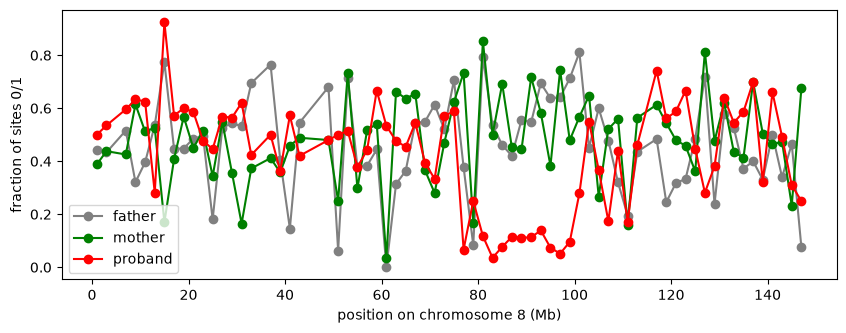

In [7]:
# One line per person along chromosome 8.
matplotlib.pyplot.figure(figsize=(10, 3.5))
matplotlib.pyplot.plot(window_middle, het_fraction_father, 'o-', color='gray', label='father')
matplotlib.pyplot.plot(window_middle, het_fraction_mother, 'o-', color='green', label='mother')
matplotlib.pyplot.plot(window_middle, het_fraction_proband, 'o-', color='red', label='proband')
matplotlib.pyplot.xlabel('position on chromosome 8 (Mb)')
matplotlib.pyplot.ylabel('fraction of sites 0/1')
matplotlib.pyplot.legend()
matplotlib.pyplot.show()

In [8]:
low_windows = []
for i in range(len(window_middle)):
    if het_fraction_proband[i] < 0.2:
        low_windows.append(window_middle[i])
        print(window_middle[i], round(het_fraction_proband[i], 2))

print("Run starts at:", low_windows[0], "Mb")
print("Run ends at:", low_windows[-1], "Mb")

77.0 0.07
81.0 0.12
83.0 0.04
85.0 0.08
87.0 0.11
89.0 0.11
91.0 0.11
93.0 0.14
95.0 0.07
97.0 0.05
99.0 0.1
107.0 0.17
111.0 0.17
Run starts at: 77.0 Mb
Run ends at: 111.0 Mb


In [9]:
print("Run starts at:", window_middle[0], "Mb")
print("Run ends at:", window_middle[-1], "Mb")

Run starts at: 1.0 Mb
Run ends at: 147.0 Mb


**What to look at.** Where does the red line (proband) drop close to zero while the parents stay high? That stretch is the run of homozygosity. Write down where it starts and ends. (It does not reach exactly zero: a few genotypes are always wrong.)

> **Try it.** Change `window_size` to 500000 (0.5 Mb) or 5000000 (5 Mb) and run the two cells again. Small windows are noisy; large windows blur the edges of the run.

In practice, runs of homozygosity are found with a statistical model that also allows for genotyping errors and finds the edges more precisely: a hidden Markov model, for example `bcftools roh` (Narasimhan et al. 2016).

---
## 3. Trio phasing: which allele came from which parent?

The VCF says the boy is `0/1` at a site, but not **which** copy came from his father and which from his mother. Working this out is called **phasing**. With a trio, Mendel's rules phase many sites:

| proband | father | mother | the boy got from father / from mother |
|---|---|---|---|
| `0/0` | any | any | `0` / `0` |
| `1/1` | any | any | `1` / `1` |
| `0/1` | `0/0` | any | `0` / `1` (the father had no `1` to give) |
| `0/1` | `1/1` | any | `1` / `0` |
| `0/1` | `0/1` | `0/0` | `1` / `0` |
| `0/1` | `0/1` | `1/1` | `0` / `1` |
| `0/1` | `0/1` | `0/1` | cannot tell |

(Other methods phase without parents: from reads that cover two variants at once, or from common haplotypes in a reference population.)

In [10]:
def phase_trio(proband, father, mother):
    # Returns (allele from father, allele from mother), or ('?', '?') if we cannot tell.
    if proband == '0/0':
        return ('0', '0')
    if proband == '1/1':
        return ('1', '1')
    if proband == '0/1':
        if father == '0/0':
            return ('0', '1')
        if father == '1/1':
            return ('1', '0')
        if mother == '0/0':
            return ('1', '0')
        if mother == '1/1':
            return ('0', '1')
    return ('?', '?')


# Apply the rules to every variant, one row at a time.
from_father = []
from_mother = []
for i in range(len(table)):
    row = table.iloc[i]
    alleles = phase_trio(row['proband'], row['father'], row['mother'])
    from_father.append(alleles[0])
    from_mother.append(alleles[1])

table['from_father'] = from_father
table['from_mother'] = from_mother

# How many of the boy's heterozygous sites could we phase?
het = table[table['proband'] == '0/1']
phased = het[het['from_father'] != '?']
print('heterozygous sites in the proband:', len(het))
print('of which phased:', len(phased))

heterozygous sites in the proband: 3153
of which phased: 2590


**What to look at.** Most of the boy's heterozygous sites can be phased (about 2,590 of 3,153): at those sites we know which allele came from his father and which from his mother. The rest are sites where both parents are `0/1`.

Why does this matter? For another recessive situation, **compound heterozygosity**: two different damaging variants in the same gene, one from each parent. Only phasing tells whether they sit on different copies (disease) or on the same copy (the other copy still works).

---
## 4. The funnel, step 1: the inheritance pattern

The parents are healthy and related, so we expect a **recessive** variant: the boy is `1/1`, and both parents are carriers, `0/1`.

In [11]:
# Recessive pattern: proband 1/1, mother 0/1, father 0/1.
candidates = table[(table['proband'] == '1/1') & (table['mother'] == '0/1') & (table['father'] == '0/1')]

print('all variants:', len(table))
print('recessive pattern:', len(candidates))

# We keep the counts of each step for a plot at the end.
funnel_steps = ['all variants', 'recessive pattern']
funnel_counts = [len(table), len(candidates)]

all variants: 6982
recessive pattern: 336


**What to look at.** Hundreds of variants fit the family. Why so many? Inside the run of homozygosity, **every** variant that both parents carry becomes `1/1` in the boy, including all the common, harmless ones. The inheritance pattern is necessary, but far from enough.

---
## 5. Annotation with Ensembl VEP

**VEP** (Variant Effect Predictor; McLaren et al. 2016) compares each variant with the known genes and tells us:

* **gene** and **consequence**: for example intron, synonymous, missense, stop-gain, frameshift,
* **impact**: a summary of how much the protein is affected (explained below),
* **SIFT** and **PolyPhen**: predictions of whether an amino-acid change damages the protein,
* the **frequency in gnomAD** and the **ClinVar** classification, if the variant is already known.

We use VEP through its **web service**: we send our variants over the internet to the Ensembl server and receive the answers. Our genome version is GRCh37 (hg19), so we use the GRCh37 server. The server accepts at most 200 variants at a time, so we send them in groups of 200.

In [12]:
# Write each variant the way VEP expects it: "8 86385980 . G A . . ."
# (chromosome without "chr", position, a dot, reference allele, alternative allele, three dots).
variant_texts = []
for i in range(len(candidates)):
    row = candidates.iloc[i]
    text = '8 ' + str(row['pos']) + ' . ' + row['ref'] + ' ' + row['alt'] + ' . . .'
    variant_texts.append(text)

print('variants to annotate:', len(variant_texts))
print('the first one:', variant_texts[0])

variants to annotate: 336
the first one: 8 441776 . C T . . .


In [13]:
# Send the variants to the VEP server, 200 at a time.
vep_results = []
start = 0
while start < len(variant_texts):
    group = variant_texts[start:start + 200]

    # "pick": 1 asks for one answer per variant (the most relevant transcript of the gene).
    response = requests.post('https://grch37.rest.ensembl.org/vep/homo_sapiens/region',
                             headers={'Content-Type': 'application/json', 'Accept': 'application/json'},
                             json={'variants': group, 'pick': 1})

    # Status 200 means "OK".
    print('variants', start, 'to', start + len(group), '- server status:', response.status_code)

    # Add the answers to our list.
    vep_results = vep_results + response.json()
    start = start + 200

print('variants annotated:', len(vep_results))

variants 0 to 200 - server status: 200
variants 200 to 336 - server status: 200
variants annotated: 336


Each answer from VEP is a nested structure (a dictionary). Let us look at the answer for one variant before we extract what we need.

In [14]:
# The answer for the first variant.
vep_results[0]

{'input': '8 441776 . C T . . .',
 'allele_string': 'C/T',
 'id': '.',
 'colocated_variants': [{'frequencies': {'T': {'gnomade': 0.1523,
     'gnomadg': 0.1467,
     'sas': 0.1871,
     'gnomade_sas': 0.2134,
     'gnomadg_fin': 0.1457,
     'gnomade_fin': 0.1398,
     'gnomade_afr': 0.07205,
     'afr': 0.0666,
     'gnomadg_nfe': 0.1466,
     'gnomadg_eas': 0.274,
     'eur': 0.1481,
     'gnomadg_afr': 0.07681,
     'gnomade_eas': 0.241,
     'gnomade_mid': 0.1464,
     'gnomadg_ami': 0.2286,
     'eas': 0.3016,
     'gnomade_amr': 0.3028,
     'gnomade_nfe': 0.1468,
     'gnomade_remaining': 0.1657,
     'gnomadg_amr': 0.2707,
     'gnomade_asj': 0.1468,
     'gnomadg_asj': 0.1377,
     'gnomadg_sas': 0.208,
     'gnomadg_mid': 0.1531,
     'af': 0.1863,
     'gnomadg_remaining': 0.1599,
     'amr': 0.3012}},
   'seq_region_name': '8',
   'allele_string': 'C/T',
   'strand': 1,
   'id': 'rs2278764',
   'end': 441776,
   'start': 441776}],
 'strand': 1,
 'end': 441776,
 'transcript_

In [15]:
# Extract the information we need from each answer, one variant at a time.
rows = []
for answer in vep_results:

    # Position: the second word of the line we sent.
    position = int(answer['input'].split()[1])

    # Gene, impact, SIFT and PolyPhen: from the transcript annotation.
    # (Variants between genes have no transcript annotation: then we use an empty one, {}.)
    transcript = answer.get('transcript_consequences', [{}])[0]
    gene = transcript.get('gene_symbol', '')
    impact = transcript.get('impact', '')
    sift = transcript.get('sift_prediction', '')
    polyphen = transcript.get('polyphen_prediction', '')

    # Frequency in gnomAD and ClinVar: from known variants at the same position.
    # 'gnomade' is the frequency in all gnomAD exomes. Empty if the variant is not in gnomAD.
    gnomad = ''
    clinvar = ''
    for known in answer.get('colocated_variants', []):
        for allele in known.get('frequencies', {}):
            gnomad = known['frequencies'][allele].get('gnomade', '')
        if 'clin_sig' in known:
            clinvar = ', '.join(known['clin_sig'])

    rows.append([position, gene, answer['most_severe_consequence'], impact, sift, polyphen, gnomad, clinvar])

annotated = pandas.DataFrame(rows, columns=['pos', 'gene', 'consequence', 'impact',
                                            'sift', 'polyphen', 'gnomad_freq', 'clinvar'])
annotated.head(10)

,pos,gene,consequence,impact,sift,polyphen,gnomad_freq,clinvar
0,441776,TDRP,intron_variant,MODIFIER,,,0.1523,
1,1729582,CLN8,3_prime_UTR_variant,MODIFIER,,,0.2143,
2,1905132,ARHGEF10,synonymous_variant,LOW,,,0.3837,benign
3,1905823,ARHGEF10,3_prime_UTR_variant,MODIFIER,,,0.4039,
4,2048640,MYOM2,intron_variant,MODIFIER,,,,
5,2048831,MYOM2,missense_variant,MODERATE,tolerated,benign,,
6,2795430,CSMD1,downstream_gene_variant,MODIFIER,,,0.3128,
7,2799981,CSMD1,intron_variant,MODIFIER,,,0.3196,
8,3166082,CSMD1,intron_variant,MODIFIER,,,0.3348,
9,6420534,ANGPT2,5_prime_UTR_variant,MODIFIER,,,0.8263,


### 5.1 The funnel, step 2: does the variant change the protein?

VEP puts every variant in one of four **impact** classes:

| impact | what happens to the protein | examples |
|---|---|---|
| **HIGH** | probably destroyed: cut short or not made correctly | stop-gain, frameshift, splice site |
| **MODERATE** | changed: one amino acid different, or a few added or removed | missense, in-frame insertion or deletion |
| **LOW** | not changed: same amino acids | synonymous |
| **MODIFIER** | not changed: the variant is outside the part of the gene that codes for protein | intron, UTR, between genes |

Careful: despite its name, **MODIFIER does not modify the protein**. It means "outside the coding sequence, effect unknown". Some of these variants can still matter (for example by changing splicing or how much of the gene is made), but they are hard to interpret, so we set them aside.

In [16]:
# How many variants in each impact class?
annotated['impact'].value_counts()

impact
MODIFIER    272
LOW          39
MODERATE     21
HIGH          4
Name: count, dtype: int64

**What to look at.** Most candidates are intronic, synonymous or outside genes (LOW or MODIFIER). An exome contains many of them, because the capture also reads the edges of the introns. We keep the variants that change the protein: impact HIGH or MODERATE.

In [17]:
changes_protein = annotated[(annotated['impact'] == 'HIGH') | (annotated['impact'] == 'MODERATE')]

funnel_steps.append('changes the protein')
funnel_counts.append(len(changes_protein))

print('variants that change the protein:', len(changes_protein))
changes_protein

variants that change the protein: 25


,pos,gene,consequence,impact,sift,polyphen,gnomad_freq,clinvar
5,2048831,MYOM2,missense_variant,MODERATE,tolerated,benign,,
12,6479042,MCPH1,missense_variant,MODERATE,tolerated,benign,0.4172,benign
48,12878807,KIAA1456,missense_variant,MODERATE,tolerated,benign,0.7216,
51,12879099,KIAA1456,missense_variant,MODERATE,tolerated,benign,0.7773,
53,12879539,KIAA1456,missense_variant,MODERATE,tolerated,benign,0.7771,
77,17743020,FGL1,missense_variant,MODERATE,tolerated,benign,0.7555,
81,17796382,PCM1,missense_variant,MODERATE,tolerated,benign,,
85,17814915,PCM1,missense_variant,MODERATE,tolerated,benign,0.7712,
104,19819724,LPL,stop_gained,HIGH,,,0.09753,benign
117,22570907,PEBP4,frameshift_variant,HIGH,,,0.3115,


### 5.2 The funnel, step 3: is the variant rare?

A variant that causes a rare, severe disease must be rare in the population. For a recessive disease, labs usually keep variants with a frequency below 1% (0.01) in gnomAD. A variant that is not in gnomAD at all (empty value) counts as rare.

In [18]:
# Keep a variant if it is not in gnomAD, or if its frequency is below 0.01.
is_rare = []
for i in range(len(changes_protein)):
    frequency = changes_protein.iloc[i]['gnomad_freq']
    if frequency == '' or float(frequency) < 0.01:
        is_rare.append(True)
    else:
        is_rare.append(False)

rare = changes_protein[is_rare]

funnel_steps.append('rare (gnomAD below 1%)')
funnel_counts.append(len(rare))

print('rare variants that change the protein:', len(rare))
rare

rare variants that change the protein: 4


,pos,gene,consequence,impact,sift,polyphen,gnomad_freq,clinvar
5,2048831,MYOM2,missense_variant,MODERATE,tolerated,benign,,
81,17796382,PCM1,missense_variant,MODERATE,tolerated,benign,,
220,86385980,CA2,stop_gained,HIGH,,,0.000001,
286,98828397,LAPTM4B,missense_variant,MODERATE,tolerated,benign,0.000029,


### 5.3 The funnel, step 4: does the gene explain the patient?

Labs often look first at a **gene panel**: the list of genes already known to cause the patient's disease. We download the panel from **PanelApp** (Genomics England; Martin et al. 2019), where clinical experts review the evidence for each gene. Each gene gets a colour:

* **green**: enough evidence to be used in diagnosis,
* **amber**: some evidence, not yet enough,
* **red**: little evidence.

We use the green genes of the panel "Osteopetrosis" (panel number 943). You can see the same panel in a web browser: https://panelapp.genomicsengland.co.uk/panels/943/

In [19]:
# Ask PanelApp for panel 943 ("Osteopetrosis").
response = requests.get('https://panelapp.genomicsengland.co.uk/api/v1/panels/943/')
print('server status:', response.status_code)

panel = response.json()
print('panel:', panel['name'], '- version', panel['version'])

# Keep the green genes. In PanelApp, green is written as confidence level '3'.
osteopetrosis_genes = []
for gene in panel['genes']:
    if gene['confidence_level'] == '3':
        osteopetrosis_genes.append(gene['gene_data']['gene_symbol'])

print('green genes:', len(osteopetrosis_genes))
print(osteopetrosis_genes)

server status: 200
panel: Osteopetrosis - version 2.3
green genes: 18
['AMER1', 'ANKH', 'CA2', 'CLCN7', 'CTSK', 'FAM20C', 'FERMT3', 'LEMD3', 'LRP5', 'OSTM1', 'PTH1R', 'RASGRP2', 'SNX10', 'SOST', 'TCIRG1', 'TGFB1', 'TNFRSF11A', 'TNFSF11']


In [20]:
# Keep the rare variants that fall in one of these genes.
in_panel = rare[rare['gene'].isin(osteopetrosis_genes)]

funnel_steps.append('known osteopetrosis gene')
funnel_counts.append(len(in_panel))

in_panel

,pos,gene,consequence,impact,sift,polyphen,gnomad_freq,clinvar
220,86385980,CA2,stop_gained,HIGH,,,0.000001,


### 5.4 The whole funnel

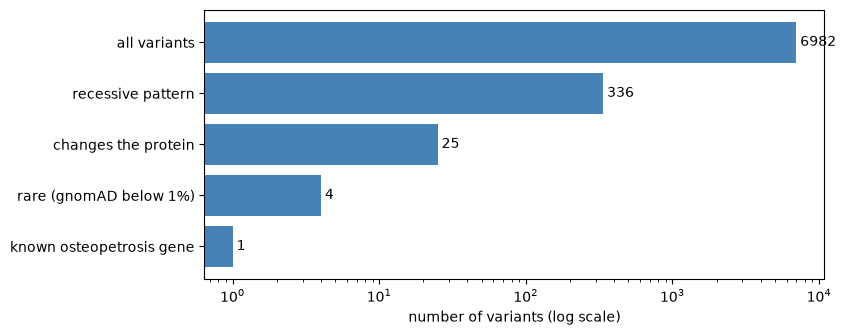

In [21]:
# One bar per step, with the number of variants left.
matplotlib.pyplot.figure(figsize=(8, 3.5))
matplotlib.pyplot.barh(funnel_steps, funnel_counts, color='steelblue')
matplotlib.pyplot.gca().invert_yaxis()       # first step on top
matplotlib.pyplot.xscale('log')              # the numbers span several orders of magnitude
for i in range(len(funnel_counts)):
    matplotlib.pyplot.text(funnel_counts[i], i, ' ' + str(funnel_counts[i]), va='center')
matplotlib.pyplot.xlabel('number of variants (log scale)')
matplotlib.pyplot.show()

**What to look at.** Which step removed the most variants? Which step used knowledge about the **patient**, not about the variant?

---
## 6. Classify the variant

**Look it up** by its position (chromosome 8, 86,385,980, G>A; genome version GRCh37) in:

* **gnomAD** (https://gnomad.broadinstitute.org, dataset gnomAD v2.1.1): how many people carry it? Is anybody homozygous?
* **ClinVar** (https://www.ncbi.nlm.nih.gov/clinvar): has it been reported? (ClinVar only contains what laboratories have submitted.)
* **OMIM** (https://omim.org): which disease does this gene cause, with which inheritance and which other symptoms?

**Classify it with the ACMG/AMP evidence from the lecture.** For each line, decide whether it applies and why:

| evidence | code | applies? why? |
|---|---|---|
| null variant (stop-gain, frameshift, splice site) in a gene where loss of function causes the disease | PVS1 (very strong) | |
| absent or extremely rare in gnomAD | PM2 (supporting) | |
| the symptoms are highly specific for this gene | PP4 (supporting) | |
| healthy people homozygous for the variant | BS2 (strong, against) | |

Under the ACMG/AMP rules, one very strong plus two supporting pieces of evidence give **pathogenic**.

### A counterexample: same gene, same pattern, not the cause

Another variant in the same gene also fits the family perfectly (proband `1/1`, parents `0/1`): position 86,386,697 C>T. Let us ask VEP about it.

In [22]:
# Send one variant to the VEP server.
response = requests.post('https://grch37.rest.ensembl.org/vep/homo_sapiens/region',
                         headers={'Content-Type': 'application/json', 'Accept': 'application/json'},
                         json={'variants': ['8 86386697 . C T . . .'], 'pick': 1})
answer = response.json()[0]

print('gene:', answer['transcript_consequences'][0]['gene_symbol'])
print('consequence:', answer['most_severe_consequence'])
print('impact:', answer['transcript_consequences'][0]['impact'])

gene: CA2
consequence: intron_variant
impact: MODIFIER


In [23]:
 
# The two candidates outside the run. 
# PCM1 AC>GT is written as its two single-base changes. 
variants = ['8 17796382 . A G . . .', 
            '8 17796383 . C T . . .', 
            '8 2048831 . A G . . .'] 
 
response = requests.post('https://grch37.rest.ensembl.org/vep/homo_sapiens/region', 
headers={'Content-Type': 'application/json', 
'Accept': 'application/json'}, 
json={'variants': variants, 'pick': 1}) 
for answer in response.json(): 
 print(answer['input'], '-', answer['most_severe_consequence']) 
for known in answer.get('colocated_variants', []): 
 print('', known.get('id'), known.get('frequencies', {})) 



8 17796382 . A G . . . - missense_variant
8 17796383 . C T . . . - synonymous_variant
8 2048831 . A G . . . - missense_variant
 COSV50745497 {}
 rs968381 {'G': {'eas': 0.4048, 'af': 0.4605, 'eur': 0.335, 'sas': 0.4192, 'amr': 0.3573, 'afr': 0.6831}}


In [25]:
import requests

# MYOM2 candidate from our VCF
chrom = "8"
pos = 2048831
rs_id = "rs968381"

# Look up the rsID in Ensembl GRCh37
url = f"https://grch37.rest.ensembl.org/variation/human/{rs_id}"
response = requests.get(
    url,
    headers={"Content-Type": "application/json"}
)

data = response.json()

print("Variant:", rs_id)

for mapping in data.get("mappings", []):
    if mapping.get("seq_region_name") == chrom and mapping.get("start") == pos:
        print("GRCh37 position:", f"chr{chrom}:{pos}")
        print("Alleles:", mapping.get("allele_string"))
        print("This matches the MYOM2 candidate at chr8:2048831.")

Variant: rs968381
GRCh37 position: chr8:2048831
Alleles: A/G
This matches the MYOM2 candidate at chr8:2048831.


In [26]:
positions = [17796382, 17796383]

for pos in positions:
    url = f"https://grch37.rest.ensembl.org/overlap/region/human/8:{pos}-{pos}"
    
    response = requests.get(
        url,
        params={"feature": "gene"},
        headers={"Content-Type": "application/json"}
    )
    
    print(f"\nchr8:{pos}")
    
    for gene in response.json():
        print("Gene:", gene.get("external_name"))
        print("Gene ID:", gene.get("id"))


chr8:17796382
Gene: PCM1
Gene ID: ENSG00000078674

chr8:17796383
Gene: PCM1
Gene ID: ENSG00000078674


In [24]:
# De novo pattern: proband 0/1, mother 0/0, father 0/0. 
de_novo = table[(table['proband'] == '0/1') & (table['mother'] == '0/0') & 
(table['father'] == '0/0')] 
print('de novo pattern:', len(de_novo)) 

de novo pattern: 38


**What to look at.** Same gene, same inheritance pattern, but it does not change the protein. A variant can fit the family perfectly and still be harmless: every step of the funnel matters.

### Open questions

1. Which variant explains the boy's osteopetrosis? What does the protein do in bone, and why does losing it make bones too dense?
2. Which other symptoms would you expect from this gene? How could a clinician check them?
3. Which step of the funnel would fail if the cause were a deletion of a whole exon, or a variant deep inside an intron?

---
## 7. Wrap-up

* Related parents can pass the same ancestral stretch of DNA to their child: a **run of homozygosity**, where a recessive variant becomes `1/1`.
* **Trio phasing** uses Mendel's rules to tell which allele came from which parent.
* The **funnel** combines independent evidence: inheritance, effect on the protein, population frequency, and the patient's disease.
* A diagnosis needs the evidence to agree. A variant that fits the family can still be harmless.

### Sources

* McLaren *et al.* (2016). The Ensembl Variant Effect Predictor. *Genome Biology* 17:122.
* Narasimhan *et al.* (2016). BCFtools/RoH: a hidden Markov model approach for detecting autozygosity from next-generation sequencing data. *Bioinformatics* 32:1749-1751.
* Karczewski *et al.* (2020). The mutational constraint spectrum quantified from variation in 141,456 humans. *Nature* 581:434-443.
* Martin *et al.* (2019). PanelApp crowdsources expert knowledge to establish consensus diagnostic gene panels. *Nature Genetics* 51:1560-1565.
* Richards *et al.* (2015). Standards and guidelines for the interpretation of sequence variants. *Genetics in Medicine* 17:405-424.